# Practice Session 01: Management of networks data. NetworkX and Pandas

*Introduction to Network Science* (2026/27), UPF

Author: <font color="blue">Pol Rovira Almirall</font>

E-mail: <font color="blue">pol.rovira02@estudiant.upf.edu</font>

Date: <font color="blue">19/10/2026</font>

# 1. Introduction to NetworkX

In [31]:
# LEAVE THIS CODE AS-IS

# Import networkx
import networkx as nx

# Import matplotlib for visualization
import matplotlib.pyplot as plt

In [32]:
# EDIT THIS CODE if needed to point to your file (as you will include it in the submission zip)

karate_club = nx.read_gml('data/karate-club/karate.gml', label=None)

In [33]:
# LEAVE THIS CODE AS-IS

# Get the list-like iterable of nodes
kc_nodes = karate_club.nodes()
print(f"Karate club nodes: {kc_nodes}")

# Get the list-like iterable of edges
kc_edges = karate_club.edges()
print(f"Karate club edges: {kc_edges}")

# We can also use other utility functions to get basic information about the graph
print(f"Number of nodes: {karate_club.number_of_nodes()}")
print(f"Number of edges: {karate_club.number_of_edges()}")

Karate club nodes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
Karate club edges: [(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 11), (1, 12), (1, 13), (1, 14), (1, 18), (1, 20), (1, 22), (1, 32), (2, 3), (2, 4), (2, 8), (2, 14), (2, 18), (2, 20), (2, 22), (2, 31), (3, 4), (3, 8), (3, 9), (3, 10), (3, 14), (3, 28), (3, 29), (3, 33), (4, 8), (4, 13), (4, 14), (5, 7), (5, 11), (6, 7), (6, 11), (6, 17), (7, 17), (9, 31), (9, 33), (9, 34), (10, 34), (14, 34), (15, 33), (15, 34), (16, 33), (16, 34), (19, 33), (19, 34), (20, 34), (21, 33), (21, 34), (23, 33), (23, 34), (24, 26), (24, 28), (24, 30), (24, 33), (24, 34), (25, 26), (25, 28), (25, 32), (26, 32), (27, 30), (27, 34), (28, 34), (29, 32), (29, 34), (30, 33), (30, 34), (31, 33), (31, 34), (32, 33), (32, 34), (33, 34)]
Number of nodes: 34
Number of edges: 78


In [34]:
# LEAVE THIS CODE AS-IS

karate_club.nodes(data=True)

# You can see the two key nodes (sensei and president) have attributes

NodeDataView({1: {'label': '1 (sensei)'}, 2: {}, 3: {}, 4: {}, 5: {}, 6: {}, 7: {}, 8: {}, 9: {}, 10: {}, 11: {}, 12: {}, 13: {}, 14: {}, 15: {}, 16: {}, 17: {}, 18: {}, 19: {}, 20: {}, 21: {}, 22: {}, 23: {}, 24: {}, 25: {}, 26: {}, 27: {}, 28: {}, 29: {}, 30: {}, 31: {}, 32: {}, 33: {}, 34: {'label': '34 (president)'}})

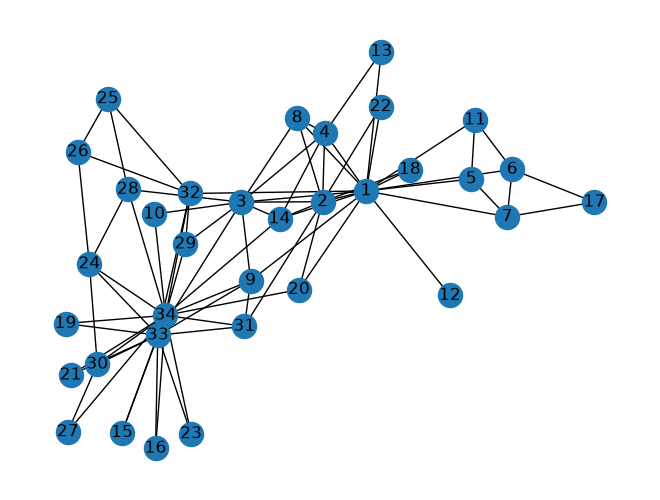

In [35]:
# LEAVE THIS CODE AS-IS

pos = nx.spring_layout(karate_club)
nx.draw(karate_club, pos=pos, with_labels=True)

## 1.1 Node and edge styles

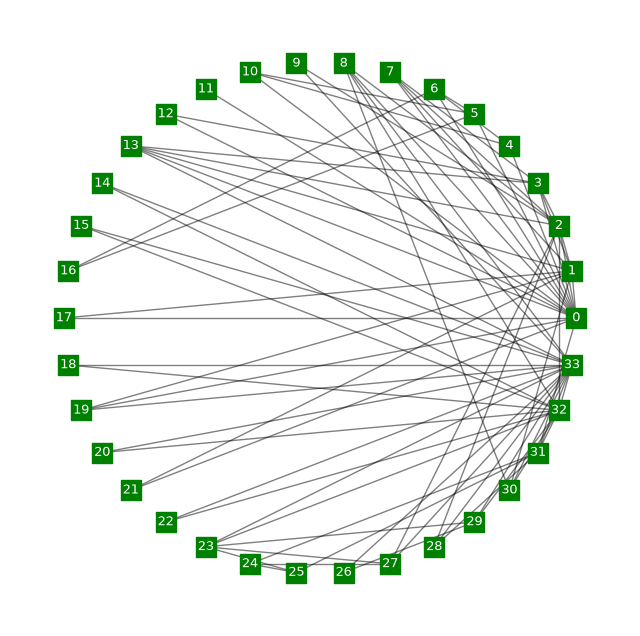

In [36]:
G = nx.karate_club_graph()
pos = nx.circular_layout(G)
plt.figure(figsize=(8, 8))

nx.draw_networkx_edges(G, pos, alpha=0.5, width=1)

nx.draw_networkx_nodes(G, pos, node_shape="s", node_color="green", node_size=200)

nx.draw_networkx_labels(G, pos, font_color="white", font_size=9)

plt.axis("off")
plt.show()

In [37]:
# LEAVE THIS CODE AS-IS

kc_node_betweenness = nx.betweenness_centrality(karate_club)
kc_edge_betweenness = nx.edge_betweenness_centrality(karate_club)

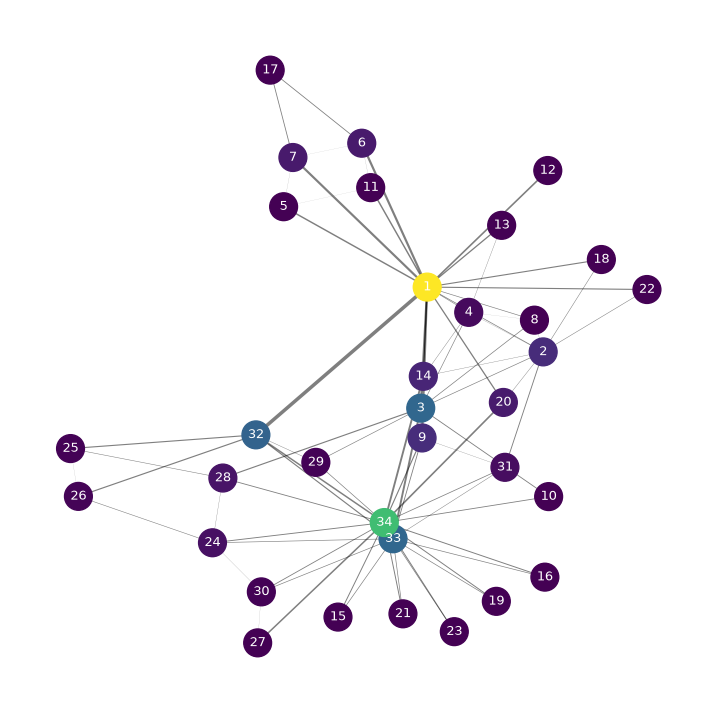

In [38]:
# 1. Posicions dels nodes (spring_layout: els nodes connectats s'acosten)
pos = nx.spring_layout(karate_club)

# 2. Llista amb la betweenness de cada node
valors_nodes = []
for node in karate_club.nodes():
    valor = kc_node_betweenness[node]
    valors_nodes.append(valor)

# 3. Llista amb el gruix de cada aresta
gruixos_arestes = []
for aresta in karate_club.edges():
    valor = kc_edge_betweenness[aresta]
    gruix = valor * 20
    gruixos_arestes.append(gruix)

# 4. Preparem la figura
plt.figure(figsize=(9, 9))

# 5. Dibuixem per capes: arestes, nodes, etiquetes
nx.draw_networkx_edges(karate_club, pos, width=gruixos_arestes, alpha=0.5)

nx.draw_networkx_nodes(
    karate_club, pos,
    node_color=valors_nodes,
    cmap=plt.cm.viridis,
    node_size=400,
)

nx.draw_networkx_labels(karate_club, pos, font_size=9, font_color="white")

# 6. Mostrem
plt.axis("off")
plt.show()

<font size="+1" color="red">Replace this cell with what "closeness centrality" and "betweenness centrality" mean, in your own words.</font>

El closeness centrality és la inversa del sumatòri de la distància entre el node i la resta de nodes. I el betweenness centrality és la quantitat de camins més curts que passen per aquell node des de la resta de nodes.

## 1.2 Drawing communities

In [39]:
with open("data/karate-club/karate-factions.csv") as file:
    next(file)                          # salta la capçalera
    for line in file:
        node_id, faction = line.split() # separa per espais/tabuladors
        karate_club.nodes[int(node_id)]["faction"] = faction

In [40]:
# LEAVE THIS CODE AS-IS

print(karate_club.nodes(data='faction'))

[(1, 'A'), (2, 'A'), (3, 'A'), (4, 'A'), (5, 'A'), (6, 'A'), (7, 'A'), (8, 'A'), (9, 'A'), (10, 'B'), (11, 'A'), (12, 'A'), (13, 'A'), (14, 'A'), (15, 'B'), (16, 'B'), (17, 'A'), (18, 'A'), (19, 'B'), (20, 'A'), (21, 'B'), (22, 'A'), (23, 'B'), (24, 'B'), (25, 'B'), (26, 'B'), (27, 'B'), (28, 'B'), (29, 'B'), (30, 'B'), (31, 'B'), (32, 'B'), (33, 'B'), (34, 'B')]


A: 17 B: 17 Sense facció: 0


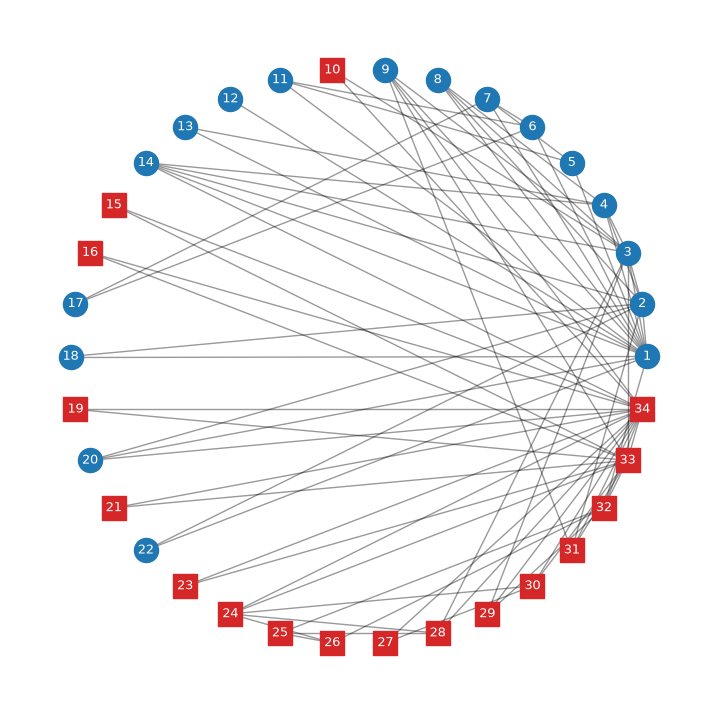

In [41]:
pos = nx.circular_layout(karate_club)

nodes_A = []
nodes_B = []
nodes_sense = []   # nodes sense facció assignada

for node, faccio in karate_club.nodes(data="faction"):
    if faccio == "A":
        nodes_A.append(node)
    elif faccio == "B":
        nodes_B.append(node)
    else:
        nodes_sense.append(node)

# Diagnòstic: A + B + sense facció han de sumar 34
print("A:", len(nodes_A), "B:", len(nodes_B), "Sense facció:", len(nodes_sense))

plt.figure(figsize=(9, 9))

nx.draw_networkx_edges(karate_club, pos, alpha=0.4)

nx.draw_networkx_nodes(karate_club, pos, nodelist=nodes_A,
                       node_color="tab:blue", node_shape="o", node_size=300)

nx.draw_networkx_nodes(karate_club, pos, nodelist=nodes_B,
                       node_color="tab:red", node_shape="s", node_size=300)

# Si algun node no té facció, es dibuixa en gris perquè no desaparegui
nx.draw_networkx_nodes(karate_club, pos, nodelist=nodes_sense,
                       node_color="gray", node_shape="^", node_size=300)

nx.draw_networkx_labels(karate_club, pos, font_size=9, font_color="white")

plt.axis("off")
plt.show()

## 1.3 Degree distribution

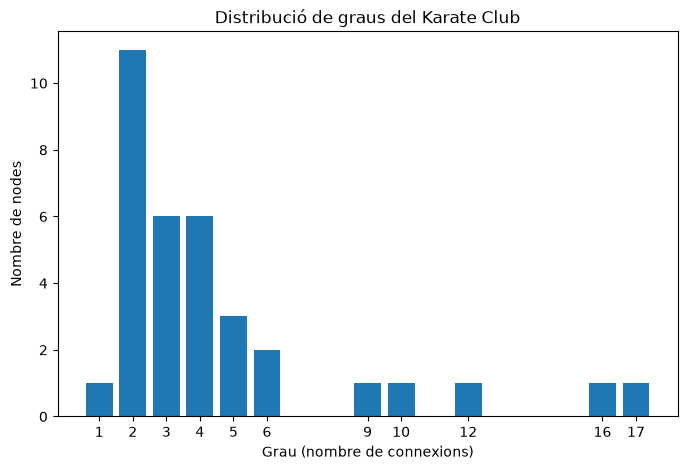

In [42]:
# 1. Creem un diccionari buit per anar comptant
# La clau serà el grau, el valor serà quants nodes tenen aquest grau
comptador = {}

# 2. Recorrem tots els nodes del graf
for node in karate_club.nodes():
    grau = karate_club.degree(node)   # el grau d'aquest node

    if grau in comptador:
        comptador[grau] = comptador[grau] + 1   # ja existia: sumem 1
    else:
        comptador[grau] = 1                     # primera vegada: comencem a 1

# 3. Preparem les dades pel gràfic
graus = []
nombre_nodes = []

for grau in sorted(comptador):
    graus.append(grau)
    nombre_nodes.append(comptador[grau])

# 4. Dibuixem
plt.figure(figsize=(8, 5))
plt.bar(graus, nombre_nodes)
plt.xlabel("Grau (nombre de connexions)")
plt.ylabel("Nombre de nodes")
plt.title("Distribució de graus del Karate Club")
plt.xticks(graus)
plt.show()

# 2. The Flavors bi-partite graph

## 2.1. Read the data into Pandas DataFrames


In [43]:
# EDIT THIS CODE if needed to point to your file (as you will include it in the submission zip)

INPUT_INGR_FILENAME = "data/flavors-network/ingredients.tsv"
INPUT_COMP_FILENAME = "data/flavors-network/compounds.tsv"
INPUT_INGR_COMP_FILENAME = "data/flavors-network/ingredient-compound.tsv"

In [44]:
# LEAVE THIS CODE AS-IS

import pandas as pd

ingredients = pd.read_csv(INPUT_INGR_FILENAME, sep="\t")
display(ingredients.head(3))

compounds = pd.read_csv(INPUT_COMP_FILENAME, sep="\t")
display(compounds.head(3))

ingr_comp = pd.read_csv(INPUT_INGR_COMP_FILENAME, sep="\t")
display(ingr_comp.head(3))

,ingredient_id,ingredient_name,ingredient_category
0,0,magnolia_tripetala,flower
1,1,calyptranthes_parriculata,plant
2,2,chamaecyparis_pisifera_oil,plant derivative


,compound_id,compound_name,compound_code
0,0,jasmone,488-10-8
1,1,5-methylhexanoic_acid,628-46-6
2,2,l-glutamine,56-85-9


,ingredient_id,compound_id
0,1392,906
1,1259,861
2,1079,673


## 2.2. Create the flavors bipartite network

In [ ]:

pas_intermedi = ingredients.merge(ingr_comp, on='ingredient_id', how='inner')
flavors = pas_intermedi.merge(compounds, on='compound_id', how='inner')
# Mostrem les primeres 10 files del dataframe 'flavors'
flavors.head(10)

,ingredient_id,ingredient_name,ingredient_category,compound_id,compound_name,compound_code
0,0,magnolia_tripetala,flower,995,diacetyl,431-03-8
1,1,calyptranthes_parriculata,plant,921,citral_(neral),5392-40-5
2,2,chamaecyparis_pisifera_oil,plant derivative,1018,undecanoic_acid,112-37-8
3,3,mackerel,fish/seafood,272,"2,4-nonadienal",6750-03-4
4,3,mackerel,fish/seafood,275,lauric_acid,143-07-7
5,3,mackerel,fish/seafood,423,vanillin,121-33-5
6,3,mackerel,fish/seafood,424,2-pentylfuran,3777-69-3
7,3,mackerel,fish/seafood,282,"vanillin,_natural",121-33-5
8,3,mackerel,fish/seafood,972,3-octen-2-one,1669-44-9
9,3,mackerel,fish/seafood,978,3-octanone,106-68-3


In [46]:
# 1. Eliminem les columnes "compound_code" i "ingredient_category"
flavors = flavors.drop(columns=['compound_code', 'ingredient_category'])

# 2. Ordenem les dades: primer per 'ingredient_name' i després per 'compound_name'
flavors = flavors.sort_values(by=['ingredient_name', 'compound_name'])

# 3. Reiniciem l'índex per fer la numeració de files neta des de 0
flavors = flavors.reset_index(drop=True)

# 4. Mostrem les primeres 10 files
flavors.head(10)

,ingredient_id,ingredient_name,compound_id,compound_name
0,1392,abies_alba,906,bornyl_acetate
1,1259,abies_alba_pine_needle,861,maltol
2,1079,abies_balsamea_oil,673,myrcene
3,22,abies_canadensis,906,bornyl_acetate
4,103,abies_concolor,906,bornyl_acetate
5,1005,abies_sibirica,906,bornyl_acetate
6,1005,abies_sibirica,171,camphene
7,1005,abies_sibirica,278,isoborneol
8,371,acacia,387,(e)-2-hexenyl_hexanoate
9,371,acacia,375,benzyl_acetate


In [47]:
# Guardem el DataFrame flavors (que conté ingredient_name i compound_name)
flavors[['ingredient_name', 'compound_name']].to_csv('flavors.tsv', sep='\t', index=False)

## 2.3. Visualize a small part of this graph

In [48]:
import networkx as nx

# Creem el graf directament des del DataFrame flavors (més segur i sense errors de lectura de fitxer)
flavors_graph = nx.from_pandas_edgelist(flavors, source='ingredient_name', target='compound_name')

In [49]:
# LEAVE THIS CODE AS-IS

print(f"Number of nodes: {flavors_graph.number_of_nodes()}")
print(f"Number of edges: {flavors_graph.number_of_edges()}")
print(f"Number of connected components: {nx.number_connected_components(flavors_graph)}")

Number of nodes: 2631
Number of edges: 36781
Number of connected components: 22


In [50]:
# 1. Creem el diccionari de categories
diccionario_categorias = ingredients.set_index('ingredient_name')['ingredient_category'].to_dict()

# 2. Afegim l'atribut 'category' als nodes del graf
nx.set_node_attributes(flavors_graph, values=diccionario_categorias, name='category')


In [51]:
# LEAVE THIS CODE AS-IS

for node in ['caffeine', 'green_tea', 'dill'] :
    print(f"{node:<10}: {flavors_graph.nodes[node]}")

caffeine  : {}
green_tea : {'category': 'plant derivative'}
dill      : {'category': 'herb'}


In [52]:
# 1. Definimos el nodo central del compuesto 'diacetyl'
nodo_central = 'diacetyl'

# 2. Buscamos los nodos a distancia 1 (vecinos directos)
vecinos_distancia_1 = set(flavors_graph.neighbors(nodo_central))

# 3. Buscamos los nodos a distancia 2 (vecinos de los vecinos)
vecinos_distancia_2 = set()
for vecino in vecinos_distancia_1:
    for vecino_de_vecino in flavors_graph.neighbors(vecino):
        vecinos_distancia_2.add(vecino_de_vecino)

# 4. Juntamos todos los nodos (distancia 1, distancia 2 y el propio nodo central)
nodos_totales = vecinos_distancia_1.union(vecinos_distancia_2)
nodos_totales.add(nodo_central)

# 5. Extraemos el subgrafo con todos estos nodos y lo guardamos en la variable obligatoria
flavors_graph_cinnamon = flavors_graph.subgraph(nodos_totales)

In [53]:
# LEAVE THIS CODE AS-IS

print(f"Number of nodes: {flavors_graph_cinnamon.number_of_nodes()}")
print(f"Number of edges: {flavors_graph_cinnamon.number_of_edges()}")
print(f"Degree of diacetyl: {flavors_graph_cinnamon.degree('diacetyl')}")

Number of nodes: 885
Number of edges: 13480
Degree of diacetyl: 112


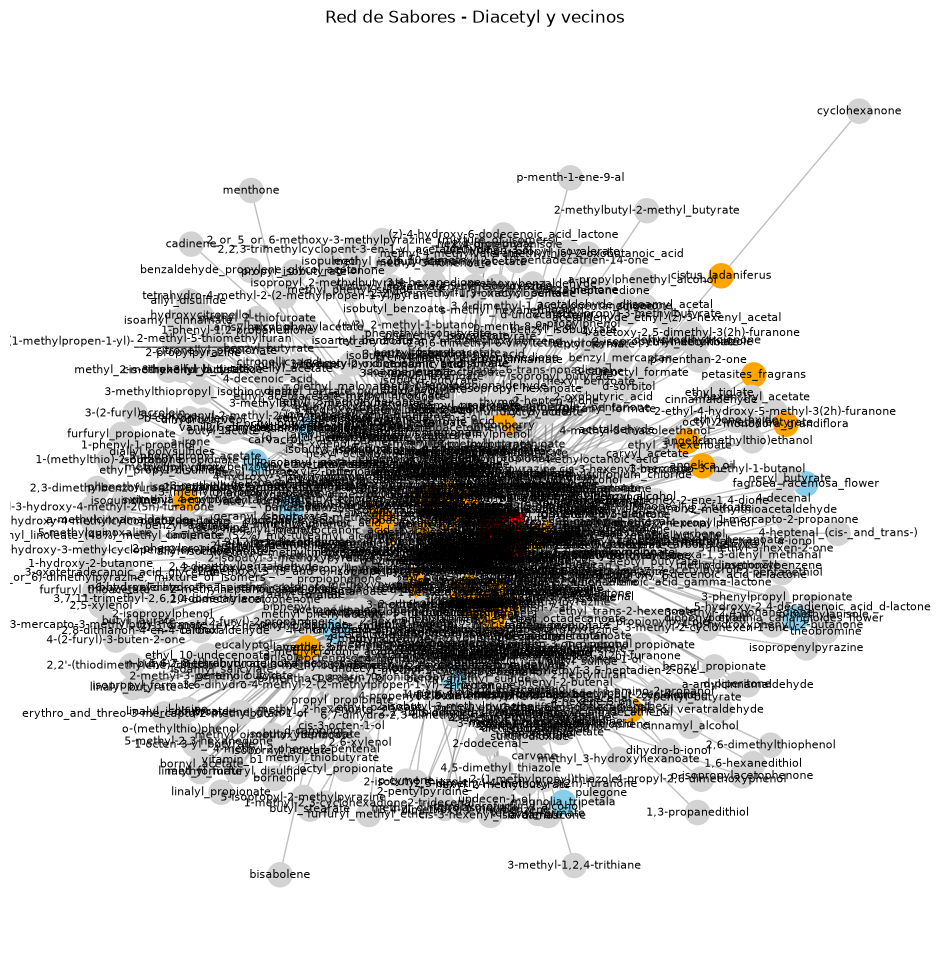

In [54]:
import matplotlib.pyplot as plt
import networkx as nx

# 1. Definimos el subgrafo que vamos a dibujar
G = flavors_graph_cinnamon

plt.figure(figsize=(12, 12))
colores_nodos = []
for nodo in G.nodes():
  # Comprobamos si el nodo tiene el atributo 'category' (es un ingrediente)
  if "category" in G.nodes[nodo] and G.nodes[nodo]["category"] is not None:
    # Puedes asignar un color fijo o dejar que coja una paleta, por ejemplo:
    categoria = G.nodes[nodo]["category"]
    colores_nodos.append("skyblue" if categoria == "flower" else "orange")
  else:
  
    colores_nodos.append("lightgray")

tamanios_nodos = [
    700 if nodo == "diacetyl" else 300 for nodo in G.nodes()
]
posiciones = nx.spring_layout(G, k=0.15, iterations=50)
# 6. Dibujamos 
nx.draw_networkx_nodes(
    G, posiciones, node_color=colores_nodos, node_size=tamanios_nodos
)
nx.draw_networkx_edges(G, posiciones, alpha=0.5, edge_color="gray")
nx.draw_networkx_labels(G, posiciones, font_size=8)
nx.draw_networkx_nodes(
    G,
    posiciones,
    nodelist=["diacetyl"],
    node_color="red",
    node_size=900,
    node_shape="s",
) 

plt.title("Red de Sabores - Diacetyl y vecinos")
plt.axis("off")
plt.show()

In [55]:
# 1. Identificamos los compuestos conectados a 'coffee' y 'tea'
vecinos_coffee = set(flavors_graph.neighbors('coffee'))
vecinos_tea = set(flavors_graph.neighbors('tea'))

# 2. Encontramos la intersección (los compuestos que comparten)
compuestos_en_comun = vecinos_coffee.intersection(vecinos_tea)

# 3. Juntamos los ingredientes principales y los compuestos comunes
nodos_subgrafo = {'coffee', 'tea'}.union(compuestos_en_comun)

# 4. Creamos el subgrafo resultante
flavors_graph_common = flavors_graph.subgraph(nodos_subgrafo)

Compostos en comú: El cafè i el te comparteixen molts compostos a la seva xarxa de sabors.

Presència de pyrazine: D’aquests, uns quants porten “pyrazine” al nom, i van lligats a aquelles notes aromàtiques i amargants tan característiques.

Exemples: Per exemple, el 2-ethylpyrazine o el 2,5-dimethylpyrazine.


Explicació del grau 2: En aquest subgraf centrat només en el cafè i el te, un node de tipus compost té grau 2 perquè està connectat exactament a dos nodes principals: el node coffee i el node tea. Si un compost només fos en un dels dos, el seu grau seria 1; per tant, un grau 2 vol dir, ras i curt, que el compost és present als dos i fa de pont entre les dues begudes alhora.

<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>
